# Chapter 81: Land, Housing, Transport, Congestion, and Urban Form

This notebook reruns four worked examples from the chapter: transit access and job offers (spatial mismatch), the bid-rent gradient, Ricardian rent as the crop price moves, and scale economies on a large estate. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def prob_at_least_one(p, n):
    """1 - (1 - p)^n."""
    return 1.0 - (1.0 - p) ** n


def search_offer_prob(p, n):
    """Chance of at least one offer from n independent applications: 1 - (1 - p)^n.

    Principle: spatial-mismatch-hypothesis. Book (ch081): p 0.20, n 5 gives 0.67232; n 7 gives 0.7902848.
    Same formula as choice.prob_at_least_one, which it calls.
    """
    return prob_at_least_one(p, n)


def feasible_attempts(hours, cash, h_each, c_each):
    """Whole applications allowed by both a time and a cash budget: min(floor(H/h), floor(M/c)).

    Principle: spatial-mismatch-hypothesis. Book (ch081): 15 hours and $60 at 3 hours and $12 gives 5;
    at 2 hours and $8 gives 7.
    """
    return int(min(math.floor(hours / h_each + 1e-9), math.floor(cash / c_each + 1e-9)))


def generalized_commute_cost(hours, fare, value_of_time):
    """Daily commute cost: hours x value of time + fare.

    Principle: spatial-mismatch-hypothesis. Book (ch081): 2($6) + $10 = $22; 1($6) + $6 = $12.
    """
    return hours * value_of_time + fare


def bid_rent(ref_bid, ref_dist, dist, cost_per_mile, floor_area):
    """Utility-preserving bid per square foot at distance dist from a reference site.

    Principle: alonso-muth-mills-bid-rent-gradient. bid = (ref_bid x area - (dist - ref_dist) x m) / area.
    Book (ch081): $30 at 2 miles, $2,000 per mile, 1,000 sq ft gives $22 at 6 miles; $1,000 per mile gives $26.
    """
    return (ref_bid * floor_area - (dist - ref_dist) * cost_per_mile) / floor_area


def ricardian_surplus(price, yields, costs):
    """Pre-rent surplus S = P x yield - delivered cost, plot by plot (list in, list out).

    Principle: ricardian-rent. Book (ch081): P 10, yields 30, 22, 14, cost 140 gives 160, 80, 0;
    P 12 gives 220, 124, 28 and plot D (yield 12, cost 144) gives 0.
    """
    return [price * y - k for y, k in zip(yields, costs)]


def tiered_total_cost(fixed, q, tiers):
    """Fixed cost plus a tiered variable cost. tiers = [(upper bound or None, rate), ...].

    Principle: economies-of-scale-latifundia. Book (ch081): 1,200 + 25(100) = 3,700;
    1,200 + 25(80) + 34(20) = 3,880; 1,200 + 25(50) = 2,450.
    """
    total, done = float(fixed), 0.0
    for upper, rate in tiers:
        top = q if upper is None else min(q, upper)
        if top > done:
            total += rate * (top - done)
            done = top
    return total


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(prob_at_least_one=prob_at_least_one)


labor = SimpleNamespace(search_offer_prob=search_offer_prob, feasible_attempts=feasible_attempts)


public = SimpleNamespace(generalized_commute_cost=generalized_commute_cost, tiered_total_cost=tiered_total_cost)


trade = SimpleNamespace(bid_rent=bid_rent)


production = SimpleNamespace(ricardian_surplus=ricardian_surplus)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'spatial-mismatch-hypothesis': {'wage': 18,
                                 'hours': 8,
                                 'daily_pay': 144,
                                 'p': 0.2,
                                 'budget_hours': 15,
                                 'budget_cash': 60,
                                 'base_app': (3, 12),
                                 'base_commute': (2, 10),
                                 'bus_app': (2, 8),
                                 'bus_commute': (1, 6),
                                 'vot': 6,
                                 'n_base': 5,
                                 'prob_base': 0.67232,
                                 'commute_base': 22,
                                 'net_base': 122,
                                 'n_bus': 7,
                                 'prob_bus': 0.7902848,
                                 'commute_bus': 12,
                                 'net_bus': 132},
 'alonso-muth-mills-bid-rent-gradient': {'area': 1000,
                                         'm': 2000,
                                         'ref_bid': 30,
                                         'ref_dist': 2,
                                         'gradient': 2,
                                         'dist': 6,
                                         'burden': 8000,
                                         'bid_6': 22,
                                         'm_rail': 1000,
                                         'burden_rail': 4000,
                                         'bid_6_rail': 26},
 'ricardian-rent': {'yields': (30, 22, 14, 12),
                    'nonland': 140,
                    'transport_D': 4,
                    'S_10': (160, 80, 0),
                    'S_12': (220, 124, 28, 0)},
 'economies-of-scale-latifundia': {'small_F': 300,
                                   'small_c': 30,
                                   'small_q': 20,
                                   'TC_S': 900,
                                   'AC_S': 45,
                                   'profit_S': -60,
                                   'F': 1200,
                                   'c': 25,
                                   'c_loss': 34,
                                   'kink': 80,
                                   'price': 42,
                                   'q': 100,
                                   'TC_L': 3700,
                                   'AC_L': 37,
                                   'profit_L': 500,
                                   'TC_loss': 3880,
                                   'AC_loss': 38.8,
                                   'profit_loss': 320,
                                   'q_low': 50,
                                   'TC_low': 2450,
                                   'AC_low': 49,
                                   'profit_low': -350},
 'constructed': {'spatial-mismatch-hypothesis': {'p': [0.1, 0.3]},
                 'alonso-muth-mills-bid-rent-gradient': {'m': [3000], 'dist': [4, 8]},
                 'ricardian-rent': {'price': [14], 'nonland': [120, 160]},
                 'economies-of-scale-latifundia': {'q': [80], 'price': [46]}}}


def prob7(x):
    """Probability with up to 7 decimals, trailing zeros removed."""
    return f"{x:.7f}".rstrip("0").rstrip(".")


def access_picture(p=0.20, access="baseline"):
    bv = BV["spatial-mismatch-hypothesis"]
    bus = access == "bus"
    h_app, c_app = bv["bus_app"] if bus else bv["base_app"]
    h_com, fare = bv["bus_commute"] if bus else bv["base_commute"]
    hours, cash, vot, pay = bv["budget_hours"], bv["budget_cash"], bv["vot"], bv["daily_pay"]
    n = labor.feasible_attempts(hours, cash, h_app, c_app)
    prob = labor.search_offer_prob(p, n)
    miss = (1 - p) ** n
    commute = public.generalized_commute_cost(h_com, fare, vot)
    net = pay - commute
    fig, (ax, bx) = new_figure(2)
    ks = np.arange(1, 9)
    probs = [labor.search_offer_prob(p, k) for k in ks]
    cols = [PALETTE["teal"] if k <= n else PALETTE["grey"] for k in ks]
    ax.bar(ks, probs, color=cols, width=0.6)
    label(ax, n, prob, f"{n} applications: {prob7(prob)}", col="navy", dx=8, dy=6, ha="right")
    ax.set_xticks(ks)
    ax.set_ylim(0, 1.12)
    ax.set_xlabel("Applications completed in the week")
    ax.set_ylabel("Chance of at least one offer")
    ax.set_title("teal bars fit the 15-hour, \\$60 budget", fontsize=10.5, color=PALETTE["ink"])
    bx.bar([0], [net], color=PALETTE["teal"], width=0.5, label="net daily pay")
    bx.bar([0], [commute], bottom=[net], color=PALETTE["terracotta"], width=0.5, label="commute cost")
    label(bx, 0.28, net / 2, f"net pay {money(net, 0)}", col="teal", dx=4, dy=0, va="center")
    label(bx, 0.28, net + commute / 2, f"commute {money(commute, 0)}", col="terracotta", dx=4, dy=0, va="center")
    bx.set_xticks([0], ["Daily pay " + money(pay, 0)])
    bx.set_xlim(-0.6, 1.6)
    bx.set_ylim(0, 165)
    bx.set_ylabel("Dollars per day")
    bx.set_xlabel("Split of one day's wage")
    mode = "the direct bus" if bus else "baseline transit"
    metrics = {"Transit": "Direct bus" if bus else "Baseline", "Applications that fit": str(n),
               "P(at least one offer)": prob7(prob), "Commute cost per day": money(commute, 0),
               "Net daily pay": money(net, 0)}
    steps = [f"Applications = min({hours} / {h_app}, {cash} / {c_app}) rounded down = {n}",
             f"P = 1 - (1 - {num(p)})^{n} = 1 - {prob7(miss)} = {prob7(prob)}",
             f"Daily pay = 18 x 8 = {money(pay, 0)}",
             f"Commute cost = {h_com}({money(vot, 0)}) + {money(fare, 0)} = {money(commute, 0)}",
             f"Net daily pay = {money(pay, 0)} - {money(commute, 0)} = {money(net, 0)}"]
    interp = (f"With {mode}, each application takes {h_app} hours and {money(c_app, 0)}, so {n} whole applications "
              f"fit the budget. The chance of at least one offer is 1 - {num(1 - p)}^{n} = {prob7(prob)}. The commute "
              f"costs {money(commute, 0)} a day, leaving {money(net, 0)} of the {money(pay, 0)} wage.")
    alt = (f"Left: chance of at least one offer for 1 to 8 applications at offer probability {num(p)}; the first {n} "
           f"bars fit the budget and reach {prob7(prob)}. Right: the {money(pay, 0)} daily wage split into "
           f"{money(commute, 0)} of commute cost and {money(net, 0)} of net pay.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bidrent_picture(m=2_000, d=6):
    bv = BV["alonso-muth-mills-bid-rent-gradient"]
    area, ref_bid, ref_dist = bv["area"], bv["ref_bid"], bv["ref_dist"]
    bid = trade.bid_rent(ref_bid, ref_dist, d, m, area)
    extra = d - ref_dist
    burden = extra * m
    grad = m / area
    fig, ax = new_figure()
    xs = np.linspace(2, 8, 50)
    for mm, col in ((1_000, "teal"), (2_000, "navy"), (3_000, "gold")):
        ys = [trade.bid_rent(ref_bid, ref_dist, x, mm, area) for x in xs]
        active = mm == m
        ax.plot(xs, ys, color=PALETTE[col], linewidth=2.6 if active else 1.3, alpha=1 if active else 0.55)
        label(ax, 8, ys[-1], f"{money(mm, 0)} per mile", col=col, dx=6, dy=0, va="center")
    mark(ax, d, bid, f"{money(bid, 0)} per sq ft at {d} miles", col="terracotta", dx=-8 if d > 5 else 8,
         dy=10, ha="right" if d > 5 else "left")
    ax.set_xlim(1.6, 10.2)
    ax.set_ylim(0, 34)
    ax.set_xticks([2, 4, 6, 8])
    ax.set_xlabel("Distance from the central job (miles)")
    ax.set_ylabel("Bid per square foot per year ($)")
    miles = "mile" if extra == 1 else "miles"
    metrics = {"Gradient ($ per sq ft per mile)": money(grad, 0), "Extra miles beyond 2": str(extra),
               "Extra commute burden": money(burden, 0), "Bid per sq ft": money(bid, 0),
               "Annual housing bid": money(bid * area, 0)}
    steps = [f"Gradient = {money(m, 0)} / 1,000 sq ft = {money(grad, 0)} per sq ft per mile",
             f"Extra burden = {extra}({money(m, 0)}) = {money(burden, 0)}",
             f"Annual bid = $30,000 - {money(burden, 0)} = {money(bid * area, 0)}",
             f"Bid per sq ft = {money(bid * area, 0)} / 1,000 = {money(bid, 0)}"]
    if extra == 0:
        interp = (f"Bid per square foot = 30 - 0 x {num(grad, 0)} = 30. At the 2-mile reference site there are no extra miles, so the bid stays at $30 per square foot. "
                  f"Each further mile lowers it by {money(grad, 0)} per square foot.")
    else:
        interp = (f"Bid per square foot = 30 - {extra} x {num(grad, 0)} = {num(bid, 0)}. Moving {extra} {miles} beyond the reference site adds {extra} x {money(m, 0)} = "
                  f"{money(burden, 0)} of commuting a year. To keep other consumption unchanged the household's "
                  f"bid falls from $30,000 to {money(bid * area, 0)}, or {money(bid, 0)} per square foot.")
    alt = (f"Bid-rent lines from 2 to 8 miles for commute costs of $1,000, $2,000 and $3,000 per mile, starting at "
           f"$30 per square foot. The active line is {money(m, 0)} per mile; at {d} miles the bid is {money(bid, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ricardo_picture(price=10, cost=140):
    bv = BV["ricardian-rent"]
    yields = bv["yields"]
    tD = bv["transport_D"]
    costs = [cost, cost, cost, cost + tD]
    S = production.ricardian_surplus(price, yields, costs)
    names = ["A", "B", "C", "D"]
    used = [s >= 0 for s in S]
    fig, ax = new_figure()
    cols = [PALETTE["teal"] if u else PALETTE["grey"] for u in used]
    ax.bar(range(4), S, color=cols, width=0.6)
    for i, s in enumerate(S):
        txt = num(s, 0) + ("" if used[i] else " (unused)")
        ax.annotate(txt, (i, s), xytext=(0, 4 if s >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if s >= 0 else "top", fontsize=10.5, color=PALETTE["ink"])
    ax.axhline(0, color=PALETTE["terracotta"], linewidth=1.6)
    ax.set_xticks(range(4), [f"{n}: {y} baskets" for n, y in zip(names, yields)])
    ax.set_ylim(-85, 340)
    ax.set_xlim(-0.6, 3.6)
    ax.set_xlabel("Plot")
    ax.set_ylabel("Pre-rent surplus S")
    label(ax, -0.55, 0, "no-rent margin S = 0", col="terracotta", dx=0, dy=-4, ha="left", va="top")
    used_S = [s for s in S if s >= 0]
    lo = min(used_S)
    margin = [n for n, s in zip(names, S) if s >= 0 and s == lo]
    margin_txt = " and ".join(margin)
    metrics = {f"S_{n}": num(s, 0) for n, s in zip(names, S)}
    metrics["Plots in use"] = ", ".join(n for n, u in zip(names, used) if u)
    steps = [f"S_{n} = {price}({y}) - {c} = {num(s, 0)}" for n, y, c, s in zip(names, yields, costs, S)]
    unused = [n for n, u in zip(names, used) if not u]
    if lo == 0:
        mtext = (f"Plot {margin_txt} earns exactly zero and is the no-rent margin, so rents on the better plots "
                 f"equal their surpluses.")
    elif unused:
        mtext = (f"No plot breaks even exactly: the least surplus in use is {num(lo, 0)} on {margin_txt}, and the "
                 f"next plot loses money, so the no-rent margin falls between them.")
    else:
        mtext = (f"Every plot earns positive surplus; the least, {num(lo, 0)} on {margin_txt}, means the no-rent "
                 f"margin lies beyond these four plots.")
    if len(unused) == 1:
        utext = f" Plot {unused[0]} would lose money at this price and stays out of use."
    elif unused:
        utext = f" Plots {' and '.join(unused)} would lose money at this price and stay out of use."
    else:
        utext = " All four plots are worth farming."
    interp = (f"At price {price} and nonland cost {cost} per hectare (D adds {tD} of transport), surplus is price times "
              f"yield minus cost: " + "; ".join(f"{n} {price} x {y} - {c} = {num(s, 0)}" for n, y, c, s in
                                                 zip(names, yields, costs, S)) + ". "
              + mtext + utext)
    alt = (f"Bars of pre-rent surplus for plots A to D at price {price} and cost {cost}: "
           + ", ".join(f"{n} {num(s, 0)}" for n, s in zip(names, S)) + ". Negative bars are grey and unused.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def estate_picture(q=100, v=25, price=42):
    bv = BV["economies-of-scale-latifundia"]
    F, c, kink = bv["F"], bv["c"], bv["kink"]
    tiers = [(kink, c), (None, v)]
    tc = public.tiered_total_cost(F, q, tiers)
    ac = tc / q
    rev = price * q
    profit = rev - tc
    ac_small = bv["AC_S"]
    fig, ax = new_figure()
    qs = np.linspace(30, 120, 200)
    ax.plot(qs, [public.tiered_total_cost(F, x, tiers) / x for x in qs], color=PALETTE["navy"], linewidth=2.2)
    label(ax, 40, public.tiered_total_cost(F, 40, tiers) / 40, "estate average cost", col="navy", dx=6, dy=4)
    hline(ax, ac_small, "small producer AC 45", col="gold", x_frac=0.70, va="bottom" if price < ac_small else "top")
    hline(ax, price, f"price {price}", col="terracotta", x_frac=0.02, va="top" if price < ac_small else "bottom")
    vline(ax, kink, "80 tons", col="grey", y_frac=0.97)
    mark(ax, q, ac, f"AC = {num(ac, 1)} at {q} tons", col="ink", dx=8 if q < 80 else -8, dy=10 if q < 80 else -10,
         ha="left" if q < 80 else "right", va="bottom" if q < 80 else "top")
    ax.set_xlim(30, 120)
    ax.set_ylim(30, 70)
    ax.set_xlabel("Estate throughput (tons)")
    ax.set_ylabel("Cost or price per ton")
    over = max(q - kink, 0)
    if over:
        tc_line = f"TC = 1,200 + 25({kink}) + {v}({over}) = {num(tc, 0)}"
    else:
        tc_line = f"TC = 1,200 + 25({q}) = {num(tc, 0)}"
    metrics = {"Total cost": num(tc, 0), "Average cost": num(ac, 1), "Revenue": num(rev, 0),
               "Profit before land cost": num(profit, 0),
               "Versus small producer AC 45": "cheaper" if ac < ac_small else ("same" if ac == ac_small else "dearer")}
    steps = [tc_line, f"AC = {num(tc, 0)} / {q} = {num(ac, 1)}", f"Revenue = {price}({q}) = {num(rev, 0)}",
             f"Profit = {num(rev, 0)} - {num(tc, 0)} = {num(profit, 0)}"]
    if over:
        vtxt = (f"The last {over} tons cost {v} each" + (", the same as the first 80." if v == c else
                                                          ", so coordination loss absorbs part of the scale gain."))
    else:
        vtxt = f"At {q} tons no output passes 80 tons, so the cost beyond 80 tons does not matter here."
    cmp = (f"{num(ac, 1)} is below the small producer's 45, a saving of {num(ac_small - ac, 1)} per ton"
           if ac < ac_small else f"{num(ac, 1)} is above the small producer's 45, so the estate is dearer per ton")
    interp = (f"{tc_line}, so average cost is {num(ac, 1)}; {cmp}. Revenue {price} x {q} = {num(rev, 0)} "
              + (f"leaves {num(profit, 0)} before land cost." if profit >= 0 else f"gives a loss of {num(-profit, 0)} before land cost.")
              + f" {vtxt}")
    alt = (f"Estate average cost from 30 to 120 tons with variable cost {v} beyond 80 tons, against the small "
           f"producer's 45 and the price {price}. At {q} tons average cost is {num(ac, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Spatial-mismatch hypothesis: bus access, job offers and net daily pay

Each application yields an offer with probability 0.20. A weekly budget of 15 hours and \$60 allows five applications at 3 hours and \$12 each.

$$1-(1-0.20)^5=1-0.8^5=0.67232.$$

The daily commute takes 2 hours and \$10, with time valued at \$6 per hour:

$$2(\$6)+\$10=\$22,$$

With a direct bus seven applications fit, and $$1-0.8^7=0.7902848.$$

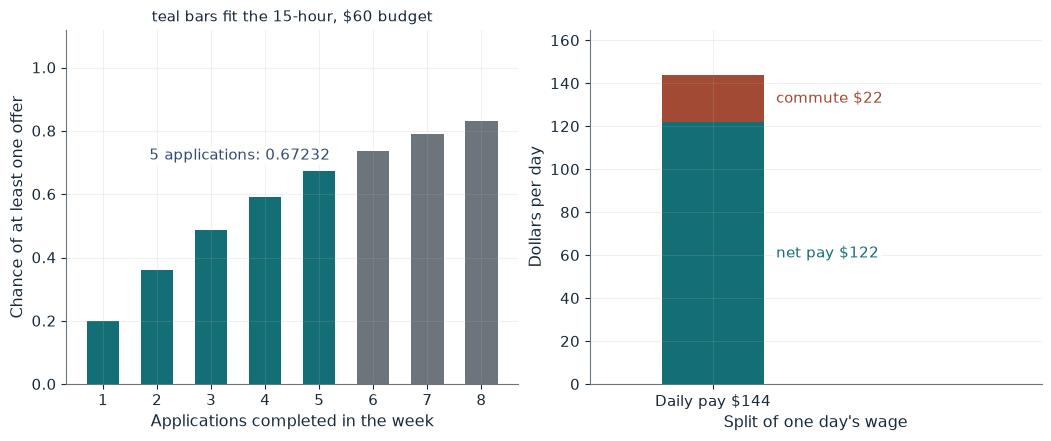

Transit                Baseline
Applications that fit  5
P(at least one offer)  0.67232
Commute cost per day   $22
Net daily pay          $122

Worked steps:
  1. Applications = min(15 / 3, 60 / 12) rounded down = 5
  2. P = 1 - (1 - 0.20)^5 = 1 - 0.32768 = 0.67232
  3. Daily pay = 18 x 8 = $144
  4. Commute cost = 2($6) + $10 = $22
  5. Net daily pay = $144 - $22 = $122

With baseline transit, each application takes 3 hours and $12, so 5 whole applications fit the budget. The chance of at least one offer is 1 - 0.80^5 = 0.67232. The commute costs $22 a day, leaving $122 of the $144 wage.


In [2]:
show(access_picture(p=0.20, access='baseline'))

Change one input, `access`, and hold the others at the book's values:

In [3]:
sweep(access_picture, 'access', ['baseline', 'bus'], {'p': 0.2}, ['Applications that fit', 'P(at least one offer)', 'Net daily pay'])

access | Applications that fit | P(at least one offer) | Net daily pay
baseline | 5 | 0.67232 | $122
bus | 7 | 0.7902848 | $132


The bus works on two margins: seven applications instead of five raise the chance of an offer from 0.67232 to 0.7902848, and the cheaper commute raises net daily pay from \$122 to \$132. If the reachable jobs need a credential the worker lacks, the offer probability is zero and access changes nothing.

## 2. Alonso-Muth-Mills bid-rent gradient: the price of a commuting mile

The household uses 1,000 square feet and bids \$30 per square foot at 2 miles. Each extra mile costs \$2,000 a year in commuting.

$$\frac{\$2{,}000}{1{,}000\text{ square feet}}=\$2$$

At 6 miles the extra burden is $$4(\$2{,}000)=\$8{,}000.$$

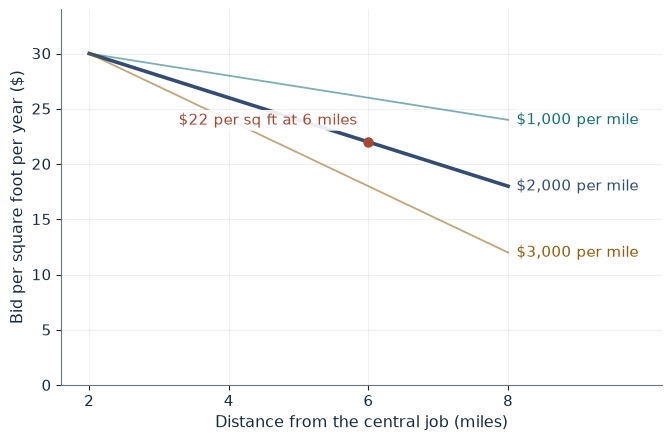

Gradient ($ per sq ft per mile)  $2
Extra miles beyond 2             4
Extra commute burden             $8,000
Bid per sq ft                    $22
Annual housing bid               $22,000

Worked steps:
  1. Gradient = $2,000 / 1,000 sq ft = $2 per sq ft per mile
  2. Extra burden = 4($2,000) = $8,000
  3. Annual bid = $30,000 - $8,000 = $22,000
  4. Bid per sq ft = $22,000 / 1,000 = $22

Bid per square foot = 30 - 4 x 2 = 22. Moving 4 miles beyond the reference site adds 4 x $2,000 = $8,000 of commuting a year. To keep other consumption unchanged the household's bid falls from $30,000 to $22,000, or $22 per square foot.


In [4]:
show(bidrent_picture(m=2_000, d=6))

Change one input, `m`, and hold the others at the book's values:

In [5]:
sweep(bidrent_picture, 'm', [1000, 2000, 3000], {'d': 6}, ['Gradient ($ per sq ft per mile)', 'Bid per sq ft'])

m | Gradient ($ per sq ft per mile) | Bid per sq ft
1000 | $1 | $26
2000 | $2 | $22
3000 | $3 | $18


At \$2,000 per mile the bid falls to \$22 per square foot at 6 miles. Rail at \$1,000 per mile halves the gradient and lifts the 6-mile bid to \$26.

## 3. Ricardian rent as price moves the margin

Plots A, B and C yield 30, 22 and 14 baskets and need 140 of nonland cost per hectare; plot D yields 12 and adds 4 of transport. At price 10:

$$S_A=10(30)-140=160,$$

$$S_B=10(22)-140=80,$$

$$S_C=10(14)-140=0.$$

At price 12 plot D comes into use: $$S_D=12(12)-144=0$$

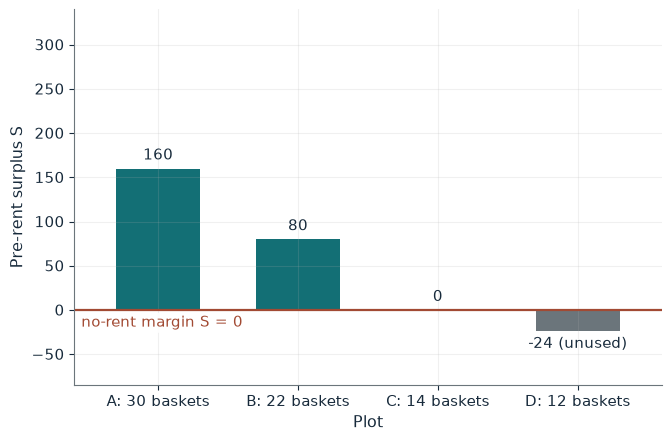

S_A           160
S_B           80
S_C           0
S_D           -24
Plots in use  A, B, C

Worked steps:
  1. S_A = 10(30) - 140 = 160
  2. S_B = 10(22) - 140 = 80
  3. S_C = 10(14) - 140 = 0
  4. S_D = 10(12) - 144 = -24

At price 10 and nonland cost 140 per hectare (D adds 4 of transport), surplus is price times yield minus cost: A 10 x 30 - 140 = 160; B 10 x 22 - 140 = 80; C 10 x 14 - 140 = 0; D 10 x 12 - 144 = -24. Plot C earns exactly zero and is the no-rent margin, so rents on the better plots equal their surpluses. Plot D would lose money at this price and stays out of use.


In [6]:
show(ricardo_picture(price=10, cost=140))

Change one input, `price`, and hold the others at the book's values:

In [7]:
sweep(ricardo_picture, 'price', [10, 12, 14], {'cost': 140}, ['S_A', 'S_B', 'S_C', 'S_D', 'Plots in use'])

price | S_A | S_B | S_C | S_D | Plots in use
10 | 160 | 80 | 0 | -24 | A, B, C
12 | 220 | 124 | 28 | 0 | A, B, C, D
14 | 280 | 168 | 56 | 24 | A, B, C, D


At price 10 plot C is the no-rent margin and rents are 160 on A and 80 on B. At price 12 plot D breaks even and becomes the margin, and surpluses rise to 220, 124 and 28. Each unit of price adds the plot's yield to its surplus, so the best land gains most.

## 4. Economies of scale and the latifundia

The small producer's cost is $$TC_S=300+30(20)=900,$$ or 45 per ton. The estate's press costs 1,200 and inputs cost 25 per ton:

$$TC_L=1{,}200+25(100)=3{,}700,$$

With coordination loss the last 20 tons cost 34 each:

$$1{,}200+25(80)+34(20)=3{,}880.$$

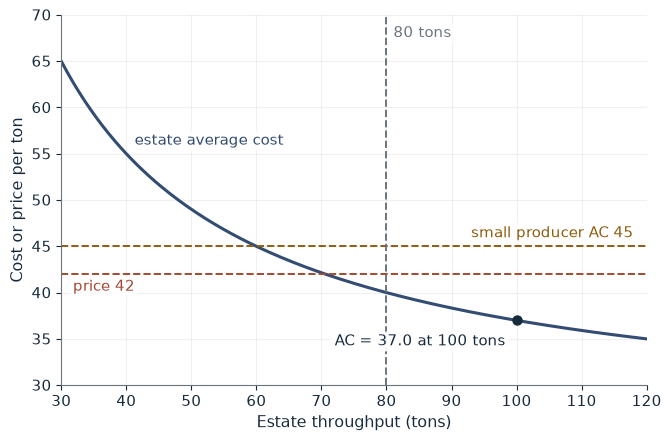

Total cost                   3,700
Average cost                 37.0
Revenue                      4,200
Profit before land cost      500
Versus small producer AC 45  cheaper

Worked steps:
  1. TC = 1,200 + 25(80) + 25(20) = 3,700
  2. AC = 3,700 / 100 = 37.0
  3. Revenue = 42(100) = 4,200
  4. Profit = 4,200 - 3,700 = 500

TC = 1,200 + 25(80) + 25(20) = 3,700, so average cost is 37.0; 37.0 is below the small producer's 45, a saving of 8.0 per ton. Revenue 42 x 100 = 4,200 leaves 500 before land cost. The last 20 tons cost 25 each, the same as the first 80.


In [8]:
show(estate_picture(q=100, v=25, price=42))

Change one input, `q`, and hold the others at the book's values:

In [9]:
sweep(estate_picture, 'q', [50, 80, 100], {'v': 25, 'price': 42}, ['Total cost', 'Average cost', 'Profit before land cost'])

q | Total cost | Average cost | Profit before land cost
50 | 2,450 | 49.0 | -350
80 | 3,200 | 40.0 | 160
100 | 3,700 | 37.0 | 500


At 100 tons the estate's average cost is 37, below the small producer's 45, and 500 remains before land cost. Coordination loss (`v=34`) raises average cost to 38.8 and cuts that to 320. At 50 tons the press is underused: average cost is 49 and the estate loses 350.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

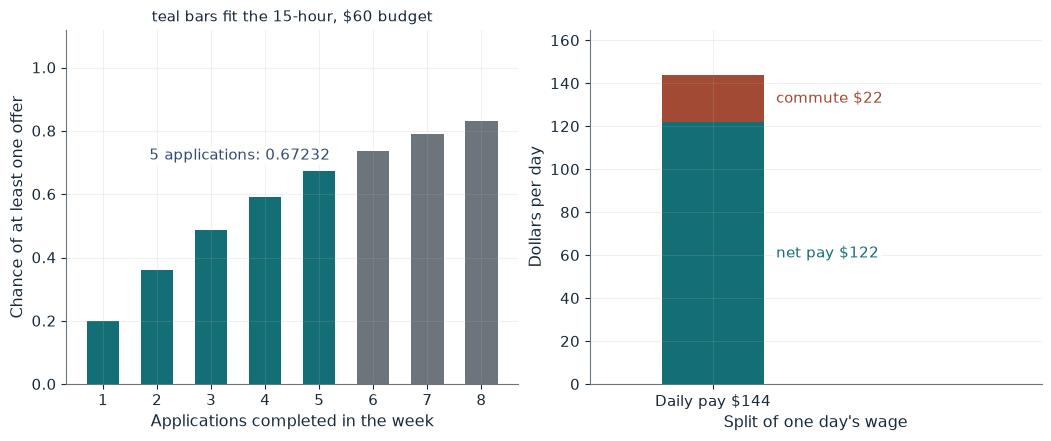

Transit                Baseline
Applications that fit  5
P(at least one offer)  0.67232
Commute cost per day   $22
Net daily pay          $122

Worked steps:
  1. Applications = min(15 / 3, 60 / 12) rounded down = 5
  2. P = 1 - (1 - 0.20)^5 = 1 - 0.32768 = 0.67232
  3. Daily pay = 18 x 8 = $144
  4. Commute cost = 2($6) + $10 = $22
  5. Net daily pay = $144 - $22 = $122

With baseline transit, each application takes 3 hours and $12, so 5 whole applications fit the budget. The chance of at least one offer is 1 - 0.80^5 = 0.67232. The commute costs $22 a day, leaving $122 of the $144 wage.


In [10]:
show(access_picture(p=0.20, access='baseline'))

## Practice

**1.** With the direct bus and offer probability 0.30, what is the chance of at least one offer?

<details><summary>Answer</summary>

7 applications fit; 1 - 0.7^7 = 1 - 0.0823543 = 0.9176457.

</details>

**2.** At \$3,000 per mile, what is the bid per square foot at 8 miles?

<details><summary>Answer</summary>

Extra burden 6 x \$3,000 = \$18,000; \$30,000 - \$18,000 = \$12,000, or \$12 per square foot.

</details>

**3.** At price 14 and cost 140, what are the surpluses on plots A to D?

<details><summary>Answer</summary>

14(30) - 140 = 280; 14(22) - 140 = 168; 14(14) - 140 = 56; 14(12) - 144 = 24.

</details>